# Código TP4: Métodos Supervisados Avanzados

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

# https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html
from sklearn.naive_bayes import MultinomialNB

# https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html
# https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.RadiusNeighborsClassifier.html
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier

# https://xgboost.readthedocs.io/en/stable/python/python_api.html
from xgboost import XGBClassifier  # Tiene interfaz estilo sklearn

# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
from sklearn.ensemble import RandomForestClassifier

# https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
# https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html
from sklearn.svm import SVC, SVR  # Clasificación / Regresión

from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score


## Carga de Datasets

News Groups Dataset: https://scikit-learn.org/stable/datasets/real_world.html#newsgroups-dataset

In [21]:
X, y = fetch_20newsgroups(subset="train",return_X_y=True, remove=("headers",))
X_train, X_val, y_train, y_val = train_test_split(X, y,test_size=0.25, random_state=1)
X_test, y_test = fetch_20newsgroups(subset="test",return_X_y=True,remove=("headers",))

print('Sample X: ', X_train[0])
print('Sample y: ', y_train[0])

topics = fetch_20newsgroups(subset="train").target_names
print(topics) 

Sample X:  |> In article <1993Apr5.220457.6800@spdc.ti.com> dwhite@epcot.spdc.ti.com (Dan White) writes:
|> 
|> >However, haven't we already lost our right to bear arms?
|> 
|> >	It seems that in most states, like Texas, a citizen may own a
|> >gun and carry while at his home or business.  But a citizen is severely
|> >restricted from bearing outside these areas.  Here in Texas you cannot
|> >carry in your car except when "traveling" which is usually defined as
|> >"traveling across a county line."  How did this come about?  Are there
|> >any court rulings on the legality of restricting the carrying of a
|> >weapon outside the home?  
|> 

In Texas, it is legal to carry handguns while "traveling", and also to and from
sporting activities.           ^^^^^^^^

Chapter 46 of the Texas State Penal Code does NOT restrict long guns.
Therefore, it is legal to carry and transport long guns any place in Texas.

Regards,
Clay


Sample y:  16
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.m

In [11]:
# spirals
esp_train = pd.read_csv("esp_train.csv", sep=',')
print(esp_train)
esp_test = pd.read_csv("esp_test.csv", sep=',')
print(esp_test)

# diagonals
diag_train = pd.read_csv("diag_train.csv", sep=',')
print(diag_train)
diag_test = pd.read_csv("diag_test.csv", sep=',')
print(diag_test)

# RRL
RRL = pd.read_csv("RRL.csv", sep=',')
print(RRL)

# Lampone
Lampone = pd.read_csv("Lampone.csv", sep=',')
print(Lampone)

     -0.932861  -0.348555  0
0     0.471330  -0.152117  0
1    -0.676675  -0.456844  0
2    -0.337246  -0.237882  0
3    -0.750397  -0.383328  0
4    -0.758688  -0.152936  0
..         ...        ... ..
994  -0.506005  -0.375704  1
995   0.909315  -0.083658  1
996   0.924952   0.271076  1
997  -0.397196   0.515772  1
998   0.244938   0.218105  1

[999 rows x 3 columns]
      0.395183  -0.838678  0
0    -0.257198  -0.813991  0
1    -0.811248   0.288827  0
2    -0.970632   0.123704  0
3     0.285026   0.602301  0
4    -0.335003   0.013217  0
...        ...        ... ..
3994  0.597976  -0.580146  1
3995 -0.659446  -0.309822  1
3996 -0.502408  -0.467037  1
3997  0.015358  -0.081344  1
3998 -0.796823   0.591190  1

[3999 rows x 3 columns]
           V1        V2  class
0   -0.631497 -0.738363      0
1   -0.430678  0.134716      0
2   -0.227673 -2.530069      0
3   -1.532579  0.066135      0
4   -0.675265 -0.358977      0
..        ...       ...    ...
295  0.337905  0.463802      1
296  2.

## Ejercicio 1: Naïve-Bayes

Vectorizamos, contando las veces que ocurre cada palabra de un diccionario dado en cada texto

In [25]:
largo_diccionario=4000
vec = CountVectorizer(stop_words='english',max_features=largo_diccionario)
Xvec_train = vec.fit_transform(X_train).toarray()
Xvec_test = vec.transform(X_test).toarray()
Xvec_val = vec.transform(X_val).toarray()

print('Sample X: ', Xvec_train[0], ' | non-zero: ', Xvec_train[0][Xvec_train[0] != 0])
print('Sample y: ', y_train[0])

Sample X:  [0 0 0 ... 0 0 0]  | non-zero:  [1 1 1 1 1 1 1 1 1 4 1 1 2 1 2 1 1 1 1 1 1 1 1 2 1 1 2 2 1 1 2 1 2 1 1 1 1
 1 5 2 1 1 1 1]
Sample y:  16


Y lo clasificamos con el clasificador discreto multinomial (pag. 180 del libro de Mitchell)


Mejor combinación en validación: dict=4000, alfa=0.1
error_train    0.1355
error_val      0.2319
error_test     0.2943


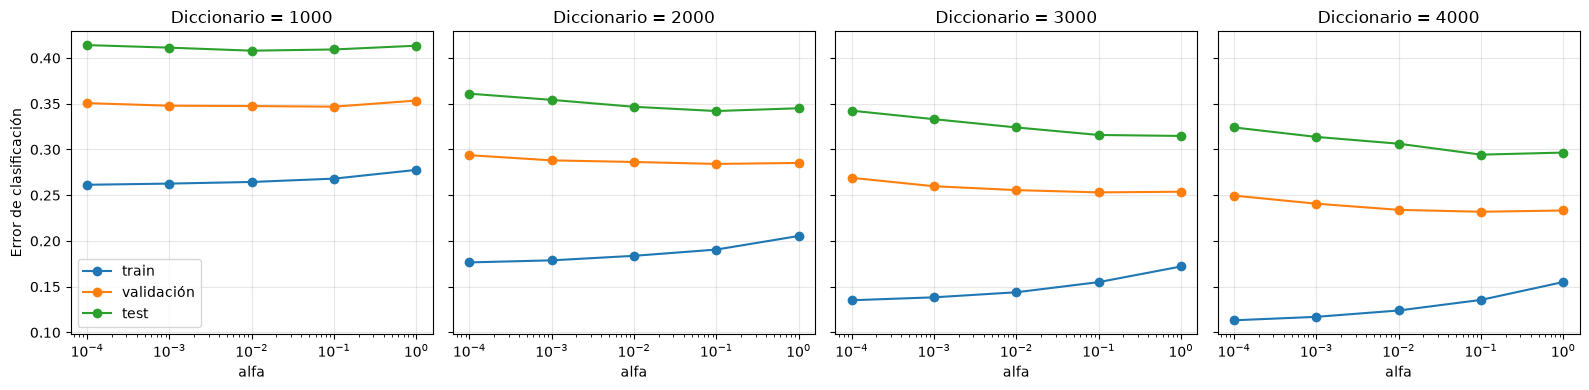

Error en test del modelo elegido: 0.2943


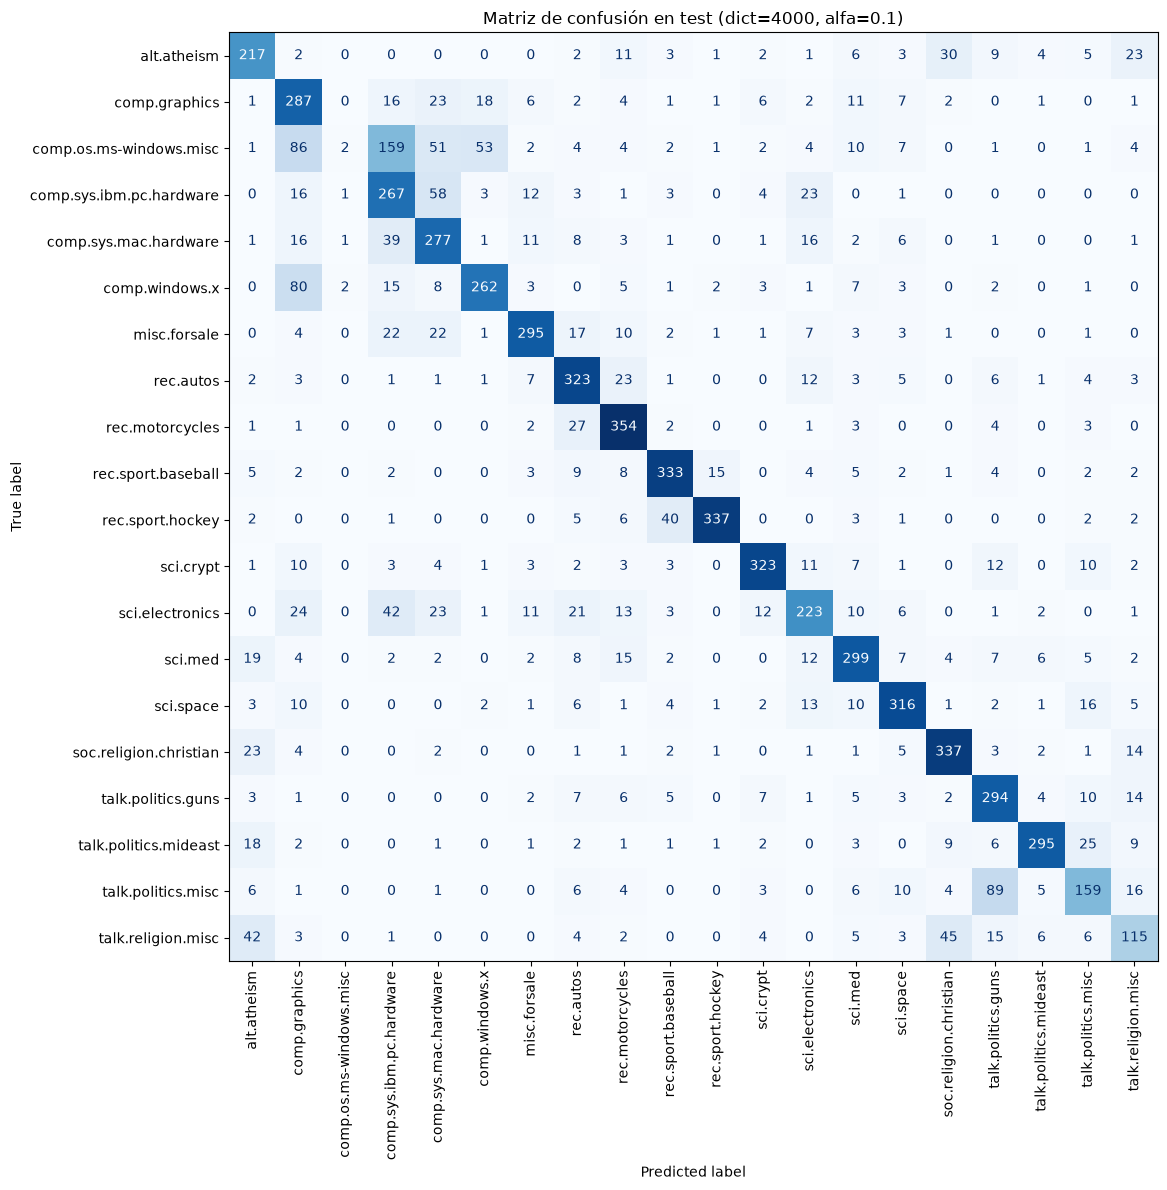

In [29]:
# Búsqueda en grilla: largo del diccionario x alfa
largos = [1000, 2000, 3000, 4000]
alfas = [1, 0.1, 0.01, 0.001, 0.0001]

resultados = []
for largo in largos:
    # El diccionario se aprende solo con train y cambia con cada largo
    vec_g = CountVectorizer(stop_words='english', max_features=largo)
    Xg_train = vec_g.fit_transform(X_train)
    Xg_val = vec_g.transform(X_val)
    Xg_test = vec_g.transform(X_test)

    for alfa in alfas:
        modelo = MultinomialNB(alpha=alfa).fit(Xg_train, y_train)
        resultados.append({
            'largo': largo,
            'alfa': alfa,
            'error_train': 1 - modelo.score(Xg_train, y_train),
            'error_val': 1 - modelo.score(Xg_val, y_val),
            'error_test': 1 - modelo.score(Xg_test, y_test),
        })

resultados = pd.DataFrame(resultados)

# La selección usa únicamente el error de validación
mejor = resultados.loc[resultados['error_val'].idxmin()]
mejor_largo, mejor_alfa = int(mejor['largo']), mejor['alfa']
print(f'\nMejor combinación en validación: dict={mejor_largo}, alfa={mejor_alfa}')
print(mejor[['error_train', 'error_val', 'error_test']].round(4).to_string())

# Curvas de error vs alfa para cada largo de diccionario
fig, axes = plt.subplots(1, len(largos), figsize=(16, 4), sharey=True)
for ax, largo in zip(axes, largos):
    sub = resultados[resultados['largo'] == largo]
    for columna, nombre in [('error_train', 'train'), ('error_val', 'validación'), ('error_test', 'test')]:
        ax.plot(sub['alfa'], sub[columna], marker='o', label=nombre)
    ax.set_xscale('log')
    ax.set_title(f'Diccionario = {largo}')
    ax.set_xlabel('alfa')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Error de clasificación')
axes[0].legend()
plt.tight_layout()
plt.show()

# Reentrenamos el modelo elegido y calculamos la matriz de confusión en test
vec_mejor = CountVectorizer(stop_words='english', max_features=mejor_largo)
Xm_train = vec_mejor.fit_transform(X_train)
Xm_test = vec_mejor.transform(X_test)
nb_mejor = MultinomialNB(alpha=mejor_alfa).fit(Xm_train, y_train)
y_pred = nb_mejor.predict(Xm_test)
print(f'Error en test del modelo elegido: {1 - accuracy_score(y_test, y_pred):.4f}')

fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=topics, xticks_rotation=90,
    cmap='Blues', colorbar=False, ax=ax
)
ax.set_title(f'Matriz de confusión en test (dict={mejor_largo}, alfa={mejor_alfa})')
plt.tight_layout()
plt.show()


El parámetro alfa controla el suavizado que se aplica a los conteos que usa el modelo para estmiar las probabilidades. Se utiliza para evitar que una palabra que nunca apareció en una clase tenga probabilidad 0.
Puede verse en el gráfico de los errores de clasificación como el error de entrenamiento aumenta a medida que aumenta el alfa, mientras que el error de validación es más alto para alfas mas chicos en diccionarios más grandes. Esto indica un poco de sobreajuste para valores chicos de alfa. Con diccionarios más grandes, al no realizarse el suavizado, el modelo ajusta a las palabras con las que realiza el entrenamiento, y esto hace que cuando se aplica el mismo modelo a artículos con palabras que no estuvieron en el entrenamiento, se producen estos casos en los que una palabra que nunca apareció hace que la clase tenga probabilidad 0. 

Con respecto al tamaño del diccionario, si puede verse una diferencia mas evidente, en la cuál los errores de entrenamiento y validación se reducen a medida que el tamaño del diccionario aumenta. Esto puede deberse a que, al ser 20 temas diferentes, el abanico de palabras necesario para reconocerlo es mayor.

También podemos ver que el comportamiento de validación es practicamente igual al de test, solo que con un error más bajo. Esto tiene sentido, ya que los datos del conjunto de validación se obtuvieron del mismo conjunto que el de entrenamiento. El comportarse de la misma forma hace

## Ejercicio 2: K-NN

In [14]:
knn_neighbors = 5
knn = KNeighborsClassifier(
    n_neighbors=knn_neighbors
)

rnn_radius = 1.0
rnn = RadiusNeighborsClassifier(
    radius=rnn_radius
)

# COMPLETAR

## Ejercicio 3: Boosting

### Ejemplo de boosting con XGBoost sobre espirales

In [15]:
esp_train_np = esp_train.to_numpy()

xgb_nrounds = 500  # total de árboles por ciclo
xgb_eta = 0.1      # learning rate (similar a redes neuronales)
xgb_maxdepth = 3   # profundidad máx de los árboles == complejidad

X = esp_train_np[:, 0:2]
y = esp_train_np[:, 2]

xgb = XGBClassifier(
    objective='binary:hinge', n_estimators=xgb_nrounds,
    learning_rate=xgb_eta, max_depth=xgb_maxdepth, colsample_bytree=1, verbosity=0,
    subsample=1)
xgb.fit(X, y, verbose=0)

xgb.score(X,y)

0.934934934934935

In [16]:
# COMPLETAR

## Ejercicio 4: Random Forests

In [17]:
rf_estimators = 1000
rf_mtry = 0

rf = RandomForestClassifier(
    n_estimators=rf_estimators,
    max_features=rf_mtry,
    bootstrap=True,
    class_weight='balanced',
    oob_score=True
)

# 1 - random_forest.oob_score_ := final out-of-bag error

# COMPLETAR

## Ejercicio 5: SVM

In [18]:
svm_kernel = 'rbf'  # 'rbf' / 'poly'
svm_C = 1.0
svm_gamma = 0.001
svm_degree = 3  # poly only, ignored otherwise

svm = SVC(
    C=svm_C,
    kernel=svm_kernel,
    gamma=svm_gamma,
    degree=svm_degree
)

# COMPLETAR